# 07. Вакансии из Telegram (2024–2026): разбор и объединение с данными hh и lalafo

**Источники:** посты Telegram-каналов, собранные через официальный Telegram API
(`kg-salary-prediction/src/collect_telegram.py`):

| Канал | Что публикует | Формат |
|---|---|---|
| @codifynews «Jobs, Работа и Вакансии из ИТ сферы» | офисные, IT, продажи, маркетинг | шаблон: название / Компания / ЗП / Тип / Дополнительно |
| @kgworkzone «Работа Бишкек, KG Work Zone» | сфера услуг, общепит, торговля, склады | свободный текст с метками 💰 🕘 📍 📌 |

Телефоны и @username в текстах заменены на `[телефон]` и `[контакт]` при сборе.

**Цель:** привести посты к той же таблице, что и данные 2024 (`vacancies_clean.csv`), с точной датой
публикации.

> **Это первая версия разбора.** Итоговый датасет 2024–2026 собирается в ноутбуке **09_master_dataset**
> по единым правилам для всех источников (`src/dataset.py`); этот ноутбук показывает, как устроены посты и разбор.

In [1]:
import re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit

sys.path.insert(0, "../src")
import telegram_parse as tp          # разбор свободного текста (kgworkzone)

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
pd.set_option("display.max_colwidth", 80)

raw = pd.read_json("../data/raw/telegram_posts.jsonl", lines=True)
raw["published"] = pd.to_datetime(raw["date"], utc=True).dt.tz_convert(None)    # UTC, как в данных 2024
log = []
def note(step, why, rows): log.append({"шаг": step, "почему": why, "строк": int(rows)})
print(f"Постов: {len(raw)}")
raw.groupby("channel").agg(постов=("text", "size"), с=("published", "min"), по=("published", "max"))

Постов: 65511


,постов,с,по
channel,,,
1093436171,20,2026-10-19 03:03:04,2026-10-28 10:00:27
codifynews,61100,2024-01-01 11:01:00,2026-10-28 09:41:10
kgworkzone,4391,2025-11-29 10:14:28,2026-10-28 11:33:12


## 1. Даты

Дата берётся из метки времени Telegram (UTC, с точностью до секунды) и хранится как в данных 2024:
колонка `published` (UTC без часового пояса), плюс `year` и `pub_month`.

**Ограничение:** это дата публикации **в канале**; канал может публиковать вакансию с задержкой
в несколько дней после её появления на сайте работодателя.

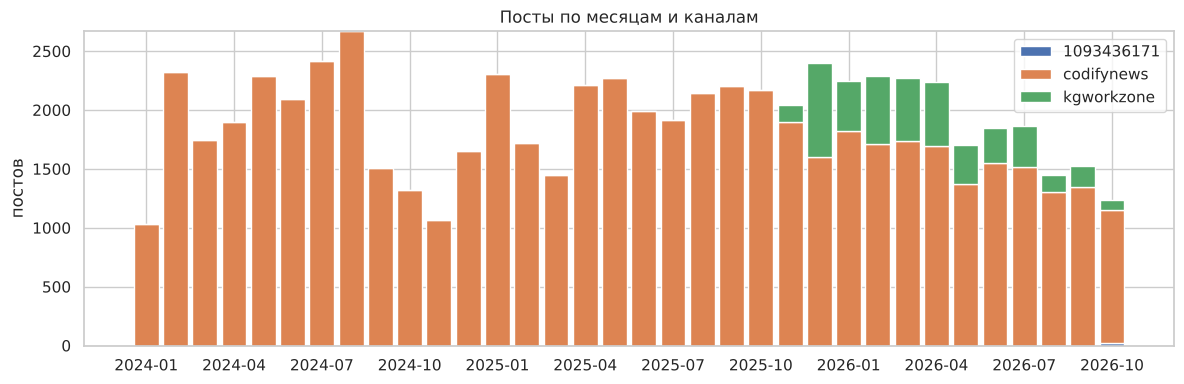

In [2]:
m = raw.groupby([raw["published"].dt.strftime("%Y-%m"), "channel"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(m))
for ch in m.columns:
    ax.bar(range(len(m)), m[ch].values, bottom=bottom, label=ch, width=0.85); bottom += m[ch].values
ax.set_title("Посты по месяцам и каналам"); ax.set_ylabel("постов"); ax.legend(title="")
ax.set_xticks(range(0, len(m), 3)); ax.set_xticklabels(m.index[::3], rotation=0)
plt.tight_layout(); plt.savefig(FIG + "07_tg_months.png", dpi=150); plt.show()

## 2. Канал с шаблоном (@codifynews)

```
Название вакансии
Компания: ...
ЗП: От 30000 до 70000 KGS в месяц
Тип: Полная занятость | office | remote ...
Дополнительно: От 1 до 3 лет, Бишкек
```
Посты не по шаблону (реклама IT-школы, подкасты, анонсы) не используются. 20 постов DevKG в другом
формате тоже не используются: их слишком мало.

In [3]:
cod = raw[raw["channel"] == "codifynews"]
is_tpl = cod["text"].str.contains("Компания:") & cod["text"].str.contains("ЗП:")
note("codify: посты не по шаблону", "реклама, анонсы, подкасты", (~is_tpl).sum())
note("DevKG: другой формат", "20 постов, слишком мало", (raw["channel"] != "codifynews").sum() - (raw["channel"] == "kgworkzone").sum())
c = cod[is_tpl].copy()
field = lambda k: c["text"].str.extract(rf"{k}:\s*(.*)")[0].str.strip()
c["name"] = c["text"].str.split("\n").str[0].str.strip()
c["company"] = field("Компания")
c["zp"] = field("ЗП")
c["type"] = field("Тип")
c["extra"] = field("Дополнительно")

z = c["zp"].fillna("")
cur = z.str.extract(r"(KGS|USD|EUR|RUB|RUR|KZT|₽|\$|€|₸|сом)", flags=re.I)[0].str.upper()
cur = cur.replace({"$": "USD", "€": "EUR", "₽": "RUB", "RUR": "RUB", "₸": "KZT", "СОМ": "KGS"})
nums = z.str.replace(r"(?<=\d)[\s\u00a0](?=\d{3})", "", regex=True).str.findall(r"\d+(?:[.,]\d+)?")
nums = nums.apply(lambda xs: [float(x.replace(",", ".")) for x in xs])
has_num = nums.str.len() > 0
lo_word = z.str.contains(r"^\s*от", case=False) & ~z.str.contains(r"\bдо\b", case=False)
hi_word = z.str.contains(r"^\s*до", case=False)
c["compensation_from"] = np.where(hi_word, np.nan, nums.str[0])
c["compensation_to"] = np.where(hi_word, nums.str[0], np.where(lo_word, np.nan, nums.str[1]))
c.loc[~has_num, ["compensation_from", "compensation_to"]] = np.nan
c["compensation_currency"] = np.where(has_num, cur.fillna("KGS"), None)
c["period_word"] = np.where(z.str.contains("в час"), "hour", np.where(z.str.contains("в месяц"), "month", None))
c["unpaid"] = z.str.contains("Неоплачиваем", case=False)

ex = c["extra"].fillna("")
exp_map = {"Без опыта": 0, "От 1 до 3 лет": 1, "От 3 до 6 лет": 3, "Более 6 лет": 6}
lvl_map = {"Стажёр": 0, "Младший": 0, "Средний": 1, "Старший": 3, "Ведущий": 6}
c["exp"] = ex.str.extract(r"^(Без опыта|От 1 до 3 лет|От 3 до 6 лет|Более 6 лет)")[0].map(exp_map) \
            .fillna(c["type"].fillna("").str.extract(r"(Стажёр|Младший|Средний|Старший|Ведущий)")[0].map(lvl_map))
c["area"] = ex.str.extract(r",\s*([^,]+)$")[0].str.strip().fillna("не указан")
c["remote"] = c["type"].fillna("").str.lower().str.contains("remote|удал")
c["requirements"] = ""
c["text_src"] = c["name"] + " " + c["type"].fillna("")
print(f"codify, вакансий по шаблону: {len(c)}")
c[["name", "company", "zp", "compensation_from", "compensation_to", "compensation_currency", "exp", "area"]].sample(8, random_state=1)

codify, вакансий по шаблону: 60781


,name,company,zp,compensation_from,compensation_to,compensation_currency,exp,area
32229,Senior Fullstack Flutter Developer,F/AI,от 300 000 ₽,300000.0,NaN,RUB,3.0,не указан
53409,Менеджер проектов,ОсОО Umai Group,Не указана,NaN,NaN,NaN,1.0,Бишкек
1445,Инженер технической поддержки [Enablement platform],МТС,Не указана,NaN,NaN,NaN,1.0,не указан
57543,Менеджер по продажам,LIBERTY SPACE,60000 - 202000 KGS,60000.0,202000.0,KGS,0.0,Бишкек
49960,Senior Back-End Developer,B.A.S.E³ Labs,От 160000 до 200000 KGS в месяц,160000.0,NaN,KGS,NaN,не указан
37325,Системный Администратор,"ГУ ""Кызмат""",От 70000 KGS в месяц,70000.0,NaN,KGS,NaN,не указан
8991,"Backend Developer (Python, Django) / Integrations Specialist",Borderless360,от 3000 $,3000.0,NaN,USD,1.0,не указан
13237,Сетевой администратор,"ОАО ""Айыл Банк""",От 120000 KGS в месяц,120000.0,NaN,KGS,NaN,не указан


## 3. Канал со свободным текстом (@kgworkzone)

Разбор в `src/telegram_parse.py`:
- отсеиваются посты, не похожие на вакансии (мемы, советы, анонсы канала);
- посты с несколькими вакансиями (блоки 🔹) делятся на отдельные вакансии;
- название: первая содержательная строка без «Вакансия», «Требуется» и эмодзи;
- зарплата: строка с «Зарплата / Оплата / ЗП / Оклад / Доход / Айлык / 💰», числа, «от / до / –», валюта;
- период: «за смену / в день» → день, «в месяц / мес» → месяц, «в час» → час;
- опыт: «без опыта / не требуется» → 0, «от N лет» → группа, «опыт обязателен / с опытом» → 1–3 года;
- город: Ош или регион, если упомянуты; иначе Бишкек (канал «Работа Бишкек»).

In [4]:
kw = tp.parse_free(raw[raw["channel"] == "kgworkzone"])
note("kgworkzone: посты не про вакансии", "мемы, советы, анонсы канала",
     (raw["channel"] == "kgworkzone").sum() - kw["msg_id"].nunique())
kw["company"] = np.nan
kw["type"] = ""
kw["remote"] = kw["text"].str.lower().str.contains(r"удал[её]нн|онлайн работ|remote")
kw["unpaid"] = False
kw["requirements"] = kw["text"].map(lambda t: re.sub(r"\s+", " ", t))
kw["text_src"] = kw["text"]
kw["id_suffix"] = kw["block"].astype(str)
multi = kw.groupby("msg_id")["block"].transform("max") > 0
print(f"kgworkzone, вакансий: {len(kw)} | из них из постов с несколькими вакансиями: {multi.sum()}")
kw[["name", "zp", "compensation_from", "compensation_to", "compensation_currency", "period_word", "exp", "area"]].sample(10, random_state=2)

kgworkzone, вакансий: 3888 | из них из постов с несколькими вакансиями: 83


,name,zp,compensation_from,compensation_to,compensation_currency,period_word,exp,area
3037,Менеджер по продажам оптовая реализация цветов,• Заработная плата от 50 000 сом и выше,50000.0,NaN,KGS,NaN,NaN,Бишкек
993,Девушки на кассу,,NaN,NaN,NaN,NaN,1.0,Бишкек
1792,КР Өзгөчө кырдаалдар министрлигинин Бишкек шаары боюнча башкармалыгы,,NaN,NaN,NaN,NaN,NaN,Бишкек
2006,Специалист по обучению за,💼 Доход: от 50 000 сом,50000.0,NaN,KGS,NaN,0.0,Регионы
480,Сотрудники в оконный цех,💰 Зарплата: от 40 000 сом,40000.0,NaN,KGS,NaN,NaN,Бишкек
1134,РАБОТНИЦЫ,— Зарплата: 1500 сом,1500.0,NaN,KGS,NaN,NaN,Регионы
571,Продавец-консультант,,NaN,NaN,NaN,NaN,0.0,Бишкек
3870,ТОРГОВЫЙ АГЕНТ В ТД «ГРАСС»,💰 Заработная плата: 40 000 – 60 000 сомов.,40000.0,60000.0,KGS,NaN,1.0,Бишкек
734,Кассир,— оплата: 2000 сом за смену,2000.0,NaN,KGS,day,1.0,Регионы
236,Ищем бариста и бабл-тишников,"3п: оклад+% от продаж, обсуждается на собеседовании +150 дорожные на вечерню...",150.0,NaN,KGS,NaN,1.0,Бишкек


## 4. Общая обработка: дубликаты, валюты, период оплаты, выбросы

**Дубликаты.** Каналы повторно публикуют вакансии. Дубликат: одинаковые название, компания и зарплата
(для kgworkzone: название и строка зарплаты). Оставляется **первая** публикация.

**Валюты.** Рубли и тенге: вакансия удаляется (работодатели из России и Казахстана, другой рынок).
USD и EUR переводятся в сомы **по курсу НБКР своего года** (середина года), чтобы не искажать зарплаты
2024 года курсом 2026:

| Год | USD | EUR | Дата курса |
|---|---|---|---|
| 2024 | 89,49 | 97,78 | 14.03.2024 (как в данных hh/lalafo 2024) |
| 2025 | 87,45 | 103,23 | 02.07.2025 |
| 2026 | 87,45 | 99,68 | 30.06.2026 |

Источник курсов: economist.kg по данным НБКР.

**Период оплаты.** Как в данных 2024: «в час» × 8 × 26; дневная ставка × 26; недельная × 4,33, если сумма
5–30 тыс.; если период не указан, суммы 500–5 000 сом считаются дневной ставкой. «Выплаты раз в неделю»
означает частоту выплат, а не размер ставки, поэтому «в месяц» в той же строке важнее. **Выбросы:** < 10 тыс. или > 600 тыс. сом обнуляются,
вакансия сохраняется.

In [5]:
cols = ["channel", "msg_id", "link", "published", "name", "company", "zp", "compensation_from", "compensation_to",
        "compensation_currency", "period_word", "unpaid", "exp", "area", "remote", "requirements", "text_src"]
c["block"] = 0
tg = pd.concat([c[cols + ["block"]], kw[cols + ["block"]]], ignore_index=True)

norm = lambda s: s.fillna("").astype(str).str.lower().str.replace(r"[^а-яёa-z0-9]+", " ", regex=True).str.strip()
tg["dup_key"] = norm(tg["name"]) + "|" + norm(tg["company"]) + "|" + norm(tg["zp"])
tg = tg.sort_values("published")
dup = tg.duplicated("dup_key", keep="first")
note("Удалены повторные публикации", "одинаковые название + компания + зарплата; оставлена первая", dup.sum())
tg = tg[~dup].copy()

foreign = tg["compensation_currency"].isin(["RUB", "KZT"])
note("Удалены вакансии в рублях и тенге", "работодатели из России и Казахстана", foreign.sum())
note("Удалены неоплачиваемые стажировки", "нет зарплаты", tg["unpaid"].sum())
tg = tg[~foreign & ~tg["unpaid"]].copy()

tg["year"] = tg["published"].dt.year
RATES = {2024: {"KGS": 1.0, "USD": 89.4870, "EUR": 97.7824},
         2025: {"KGS": 1.0, "USD": 87.45, "EUR": 103.2347},
         2026: {"KGS": 1.0, "USD": 87.45, "EUR": 99.6843}}
f, t = tg["compensation_from"], tg["compensation_to"]
tg["salary_type"] = np.select([f.notna() & t.notna(), f.notna(), t.notna()], ["range", "from", "to"], default="hidden")
raw_sal = pd.Series(np.where(f.notna() & t.notna(), (f + t) / 2, f.fillna(t)), index=tg.index)
rate = [RATES[y].get(cu, np.nan) if isinstance(cu, str) else np.nan for y, cu in zip(tg["year"], tg["compensation_currency"])]
tg["salary_kgs"] = raw_sal * np.array(rate, dtype=float)
note("Пересчёт USD/EUR в сомы", "курс НБКР своего года", tg["compensation_currency"].isin(["USD", "EUR"]).sum())

s = tg["salary_kgs"]
hour = (tg["period_word"] == "hour") & s.notna()
day = ((tg["period_word"] == "day") | (tg["period_word"].isna() & s.between(500, 5000, inclusive="left"))) & s.notna() & ~hour
week = (tg["period_word"] == "week") & s.between(5_000, 30_000, inclusive="left")    # как в 2024: только правдоподобные недельные суммы
tg.loc[hour, "salary_kgs"] *= 8 * 26
tg.loc[day, "salary_kgs"] *= 26
tg.loc[week, "salary_kgs"] *= 4.33
tg["pay_period"] = np.select([hour, day, week, s.notna()], ["hour", "day", "week", "month"], default=None)
tg["pay_period"] = tg["pay_period"].replace("None", None)
for k, m_ in [("hour", hour), ("day", day), ("week", week)]:
    note(f"Ставка «{k}» пересчитана в месяц", {"hour": "× 208", "day": "× 26", "week": "× 4,33"}[k], m_.sum())

out = tg["salary_kgs"].notna() & ((tg["salary_kgs"] < 10_000) | (tg["salary_kgs"] > 600_000))
note("Зарплата < 10 тыс или > 600 тыс обнулена", "как в данных 2024; вакансия сохранена", out.sum())
tg["salary_outlier"] = out
tg.loc[out, "salary_kgs"] = np.nan
tg["salary_hidden"] = tg["salary_type"] == "hidden"
tg["has_salary"] = tg["salary_kgs"].notna()
pd.crosstab(tg["channel"], tg["pay_period"].fillna("скрыта"))

pay_period,day,hour,month,скрыта
channel,,,,
codifynews,15,272,16554,12122
kgworkzone,536,17,1146,1347


In [6]:
chk = tg[tg["zp"].fillna("").str.contains(r"\d")].sample(15, random_state=3)
chk[["channel", "zp", "compensation_from", "compensation_to", "compensation_currency", "pay_period", "salary_kgs"]]

,channel,zp,compensation_from,compensation_to,compensation_currency,pay_period,salary_kgs
35734,codifynews,150000 - 200000 KGS,150000.0,200000.0,KGS,month,175000.0
52142,codifynews,От 60000 KGS в месяц,60000.0,NaN,KGS,month,60000.0
33245,codifynews,40000 - 60000 KGS,40000.0,60000.0,KGS,month,50000.0
38407,codifynews,От 2000 до 3500 USD в месяц,2000.0,NaN,USD,month,174900.0
31601,codifynews,от 70000 KGS,70000.0,NaN,KGS,month,70000.0
63571,kgworkzone,💰 Зарплата: 60 000 сом,60000.0,NaN,KGS,month,60000.0
63611,kgworkzone,💰 Зарплата: от 1900 +,1900.0,NaN,KGS,day,49400.0
44640,codifynews,От 10000 до 50000 KGS в месяц,10000.0,NaN,KGS,month,10000.0
61909,kgworkzone,— Заработная плата: 3000–3700 сом за смену,3000.0,3700.0,KGS,day,87100.0
12058,codifynews,25000 - 40000 KGS,25000.0,40000.0,KGS,month,32500.0


## 5. Опыт, город, сфера и профессия

- опыт не указан: группа «не указан», `experience_start` = 1 (самое частое значение),
  флаг `experience_known = False`;
- город не указан: «не указан»;
- **сфера и профессия** предсказываются классификатором по **названию вакансии**, обученным на 2024
  (TF-IDF по буквам и словам + линейный SVM); колонка `category_predicted = True`.

In [7]:
tg["experience_known"] = tg["exp"].notna()
tg["experience_start"] = tg["exp"].fillna(1).astype(int)
tg["experience"] = np.where(tg["experience_known"],
                            tg["experience_start"].map({0: "нет опыта", 1: "1–3 года", 3: "3–6 лет", 6: "6+ лет"}),
                            "не указан")
tg["city"] = np.select([tg["area"] == "Бишкек", tg["area"] == "Ош", tg["area"] == "не указан"],
                       ["Бишкек", "Ош", "не указан"], default="Регионы")

v24 = pd.read_csv("../data/processed/vacancies_clean.csv", parse_dates=["published"], low_memory=False)
def clf():
    return make_pipeline(make_union(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)), LinearSVC(C=0.5))
title24 = v24["name"].fillna("").str.lower()
grp = title24.str.replace(r"[^а-яёa-z]+", " ", regex=True)
a, b = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(v24, groups=grp))
title_tg = tg["name"].fillna("").str.lower()
for col in ["category", "sub_category"]:
    acc = (clf().fit(title24.iloc[a], v24[col].iloc[a]).predict(title24.iloc[b]) == v24[col].iloc[b]).mean()
    print(f"{col}: точность на отложенных вакансиях 2024: {acc:.0%}")
    tg[col] = clf().fit(title24, v24[col]).predict(title_tg)
tg["category_predicted"] = True
pd.crosstab(tg["category"], tg["channel"]).sort_values("kgworkzone", ascending=False).head(15)

category: точность на отложенных вакансиях 2024: 81%


sub_category: точность на отложенных вакансиях 2024: 76%


channel,codifynews,kgworkzone
category,,
"Туризм, гостиницы, рестораны",267,862
Другое,2116,466
Розничная торговля,160,320
"Продажи, обслуживание клиентов",7998,290
"Строительство, недвижимость",1671,242
"Транспорт, логистика, перевозки",86,193
"Наука, образование",252,109
"Производство, сервисное обслуживание",107,103
"Маркетинг, реклама, PR",3533,86


## 6. Остальные колонки как в 2024 и объединение

In [8]:
t = (tg["name"].fillna("") + " " + tg["text_src"].fillna("")).str.lower()
tg["education"] = np.select([t.str.contains(r"высше\w* образован|бакалавр|магистр"),
                             t.str.contains(r"средне\w*[- ]?специальн|колледж")],
                            ["высшее", "среднее специальное"], default="не указано")
female = t.str.contains(r"девушк|женщин|аял киши|кыздар|\bкыз\b"); male = t.str.contains(r"\bпарн|мужчин|эркек|жигит")
tg["gender_req"] = np.select([female & ~male, male & ~female, female & male],
                             ["женщины", "мужчины", "оба указаны"], default="не указано")
tg["schedule"] = t.str.extract(r"\b([1-7]/[1-7])\b")[0].fillna("не указан")
tg["commission"] = t.str.contains(r"процент|% от|бонус")
tg["kyrgyz_text"] = t.str.contains("[өүң]")
tg["skills"] = np.nan
tg["n_skills"] = 0
tg["text_len"] = tg["requirements"].fillna("").str.len()
tg["responsibilities"] = ""
tg["id"] = "tg_" + tg["channel"] + "_" + tg["msg_id"].astype(str) + "_" + tg["block"].astype(str)
tg["source"] = "telegram_" + tg["channel"]
tg["pub_month"] = tg["published"].dt.to_period("M").astype(str)

v24 = v24.assign(year=v24["published"].dt.year, category_predicted=False, experience_known=True)
keep = list(v24.columns)
combined = pd.concat([v24, tg[keep]], ignore_index=True)
combined["period"] = np.where(combined["source"].str.startswith("telegram"), "Telegram", "hh + lalafo (2024)")
# Итоговый датасет больше не сохраняется здесь: его собирает ноутбук 09 (мастер-датасет) по единым правилам.

log_df = pd.DataFrame(log)
log_df.loc[len(log_df)] = {"шаг": "Итого вакансий из Telegram", "почему": f"было {len(raw)} постов", "строк": len(tg)}
display(log_df)
combined.groupby(["source", "year"]).agg(вакансий=("id", "size"), с_зарплатой=("has_salary", "sum"),
                                        скрыта=("salary_hidden", "mean"), медиана=("salary_kgs", "median")) \
        .query("вакансий >= 50").style.format({"скрыта": "{:.0%}", "медиана": "{:,.0f}"})

,шаг,почему,строк
0,codify: посты не по шаблону,"реклама, анонсы, подкасты",319
1,DevKG: другой формат,"20 постов, слишком мало",20
2,kgworkzone: посты не про вакансии,"мемы, советы, анонсы канала",548
3,Удалены повторные публикации,одинаковые название + компания + зарплата; оставлена первая,29364
4,Удалены вакансии в рублях и тенге,работодатели из России и Казахстана,3026
5,Удалены неоплачиваемые стажировки,нет зарплаты,270
6,Пересчёт USD/EUR в сомы,курс НБКР своего года,3790
7,Ставка «hour» пересчитана в месяц,× 208,289
8,Ставка «day» пересчитана в месяц,× 26,551
9,Ставка «week» пересчитана в месяц,"× 4,33",0


## 7. Покрытие по времени и сферам

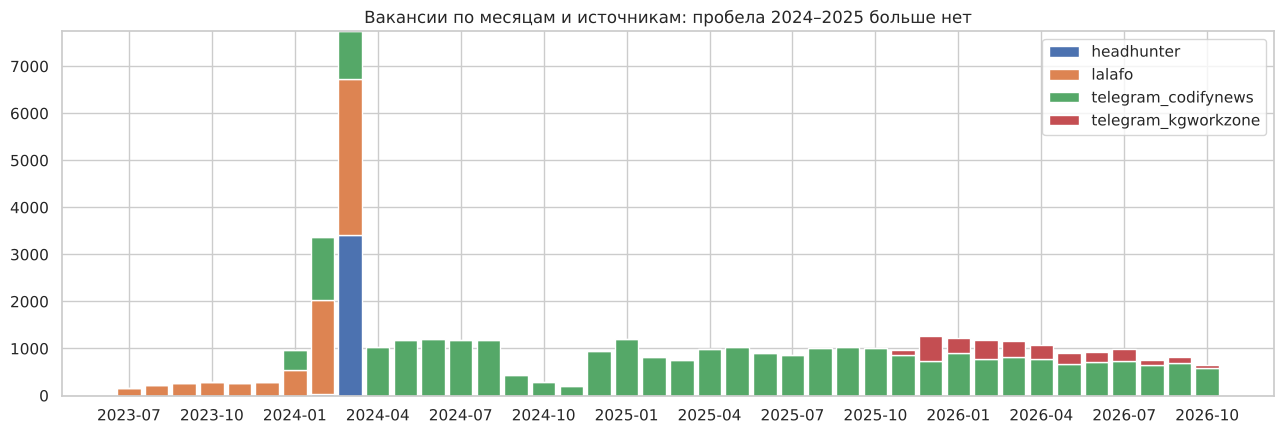

source,headhunter,lalafo,telegram_codifynews,telegram_kgworkzone
category,,,,
"Продажи, обслуживание клиентов",501,383,5817,202
"Финансы, бухгалтерия",211,60,342,32
Другое,157,289,1015,167
"Туризм, гостиницы, рестораны",157,805,144,471
Розничная торговля,147,227,116,232
"Транспорт, логистика, перевозки",147,455,59,124
"Строительство, недвижимость",140,316,956,149
Административный персонал,121,79,201,37
"Маркетинг, реклама, PR",98,74,2196,55


In [9]:
cm = combined[combined["published"] >= "2023-07-01"]
mon = cm.groupby([cm["published"].dt.strftime("%Y-%m"), "source"]).size().unstack(fill_value=0)
mon = mon.reindex(pd.period_range("2023-07", "2026-10", freq="M").strftime("%Y-%m"), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4.5))
bottom = np.zeros(len(mon))
for src in mon.columns:
    ax.bar(range(len(mon)), mon[src].values, bottom=bottom, label=src, width=0.85); bottom += mon[src].values
ax.set_xticks(range(0, len(mon), 3)); ax.set_xticklabels(mon.index[::3], rotation=0)
ax.set_title("Вакансии по месяцам и источникам: пробела 2024–2025 больше нет"); ax.legend(title="")
plt.tight_layout(); plt.savefig(FIG + "07_coverage.png", dpi=150); plt.show()

sal = combined[combined["has_salary"]]
pd.crosstab(sal["category"], sal["source"]).sort_values("headhunter", ascending=False)

## Выводы и ограничения

**Что получилось:**
- Из 65 511 постов получено **32 010 уникальных вакансий** с января 2024 по октябрь 2026, из них
  **18 342 с зарплатой**. Повторные публикации составляли почти половину постов (29 363).
- **Пробела во времени больше нет:** вакансии есть в каждом из 34 месяцев. Тоньше всего октябрь
  и ноябрь 2024 (293 и 213 вакансий), больше всего февраль 2024, декабрь 2025 и январь 2026 (1 219–1 357).
- **Даты точные:** метка времени Telegram первой публикации вакансии.
- **Зарплата:** 14 644 в сомах, 3 513 в долларах, 185 в евро (по курсу НБКР своего года);
  3 026 вакансий в рублях и тенге удалены как другой рынок.
- **Объединённая таблица первой версии** (в файл не сохраняется, итог в ноутбуке 09): **44 656 вакансий**
  (12 646 hh + lalafo и 32 010 из Telegram) с одинаковыми колонками; `source`, `year`, `period`
  отличают источники и годы.

| Источник | Год | Вакансий | С зарплатой | Скрыта | Медиана, сом |
|---|---|---|---|---|---|
| hh | 2024 | 3 437 | 2 028 | 41% | 40 000 |
| lalafo | 2024 | 5 855 | 2 340 | 56% | 35 000 |
| Telegram: codifynews | 2024 | 10 470 | 5 539 | 46% | 60 500 |
| Telegram: codifynews | 2025 | 11 200 | 6 409 | 42% | 65 000 |
| Telegram: codifynews | 2026 | 7 294 | 4 713 | 35% | 70 000 |
| Telegram: kgworkzone | 2025 (с ноября) | 656 | 243 | 62% | 40 000 |
| Telegram: kgworkzone | 2026 | 2 390 | 1 438 | 39% | 50 000 |

**Ограничения, которые важно учитывать в анализе:**
1. **Источники различаются по составу:** codifynews в основном офисные, IT и продажные вакансии
   (медиана выше), kgworkzone и lalafo сфера услуг и общепит. Сравнивать годы нужно **внутри одного
   источника** (codifynews 2024 → 2025 → 2026) или **по одинаковым профессиям**.
2. **В феврале–марте 2024 есть и hh, и codifynews:** это позволяет измерить разницу самих источников
   за один и тот же период.
3. **kgworkzone начинается только с ноября 2025:** для сферы услуг сравнение лет возможно
   только через lalafo 2024 против kgworkzone 2025–2026.
4. **Сфера и профессия предсказаны** классификатором по названию (точность на 2024: 81% и 76%).
5. **Опыт известен у 73% вакансий Telegram, город у 57%;** у codifynews много удалённых вакансий без города.
6. В codifynews есть **международные удалённые** вакансии в долларах и евро: это часть рынка, доступного
   специалистам из Кыргызстана, но не местные зарплаты.
7. Дневные ставки пересчитаны как 26 смен в месяц, как в 2024; при графике 2/2 это завышает месячную сумму.

**Попутно найдено:** в справочнике источника 2024 профессия «Менеджер по продажам» была отнесена к сфере
«Спортивные клубы, фитнес, салоны красоты»; исправлено в `02_cleaning`.